# 🧠 Brain Stroke CT Scan Classification with Deep Learning
An improved model pipeline using data augmentation, transfer learning, and extensive visualization for better accuracy and understanding.

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc


## 📁 Load and Structure Dataset

In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "Brain_Stroke_CT_Dataset/Training",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(150, 150),
    batch_size=32,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "Brain_Stroke_CT_Dataset/Training",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(150, 150),
    batch_size=32,
    label_mode="categorical"
)

class_names = train_ds.class_names
num_classes = len(class_names)


Found 5558 files belonging to 2 classes.
Using 4447 files for training.
Found 5558 files belonging to 2 classes.
Using 1111 files for validation.


## 🔄 Data Augmentation

In [3]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])


## 🧹 Optimize Dataset Pipeline

In [4]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


## 🏗️ Build the Model with Transfer Learning

In [5]:
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])


## ⚙️ Compile the Model

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


## ⏱️ Callbacks

In [37]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.1, patience=3),
    tf.keras.callbacks.ModelCheckpoint("best_model.h5", save_best_only=True)
]


## 🚆 Train the Model

In [38]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1,
    callbacks=callbacks
)


139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8115 - loss: 0.4385

139/139 ━━━━━━━━━━━━━━━━━━━━ 244s 2s/step - accuracy: 0.8115 - loss: 0.4386 - val_accuracy: 0.8227 - val_loss: 0.4435 - learning_rate: 1.0000e-06


## 📊 Training and Validation Metrics

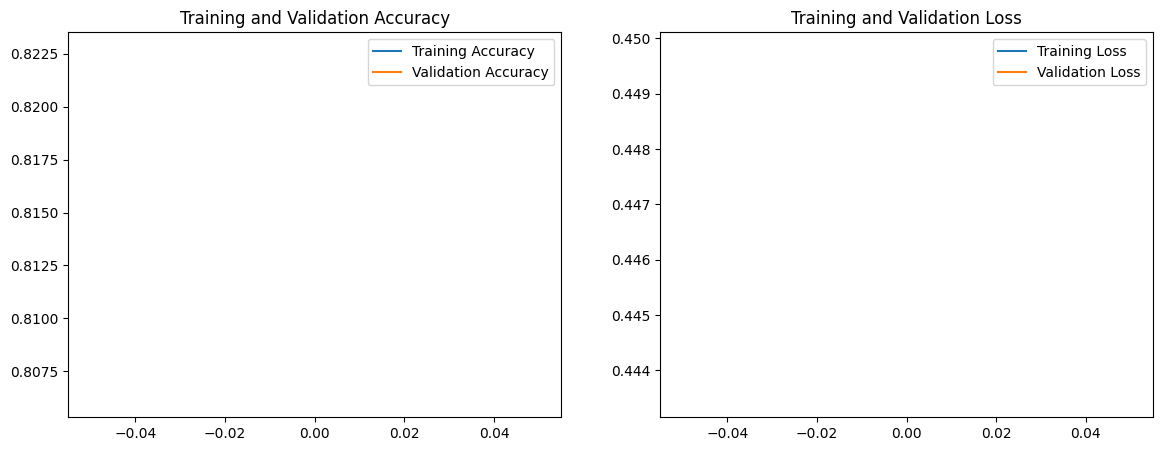

In [39]:
def plot_training(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(acc, label='Training Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.legend()
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(loss, label='Training Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.legend()
    plt.title('Training and Validation Loss')

    plt.show()

plot_training(history)


## 📉 Confusion Matrix and ROC Curve

35/35 ━━━━━━━━━━━━━━━━━━━━ 15s 337ms/step


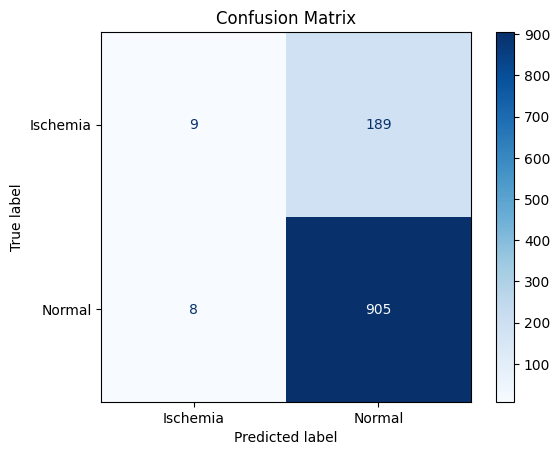

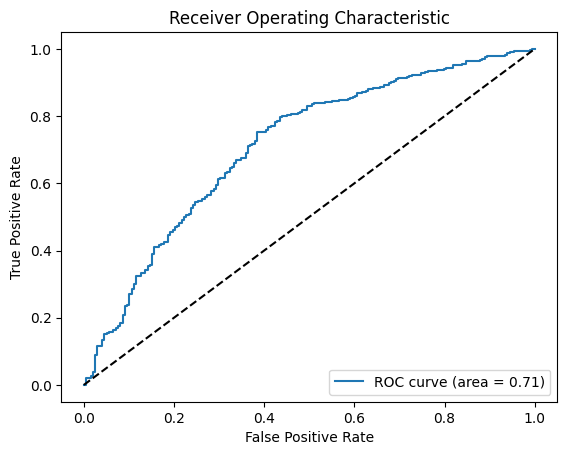

In [40]:
y_pred_probs = model.predict(val_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y for x, y in val_ds])
y_true = np.argmax(y_true, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

# ROC Curve (for binary classification)
if num_classes == 2:
    fpr, tpr, _ = roc_curve(y_true, y_pred_probs[:, 1])
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:0.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc='lower right')
    plt.show()


## 🔧 Fine-Tuning the Pretrained Model

In [ ]:
# Unfreeze the base model for fine-tuning
base_model.trainable = True

# Recompile with a lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=callbacks
)


## 📉 Learning Rate Schedule Visualization

Plotting should start now


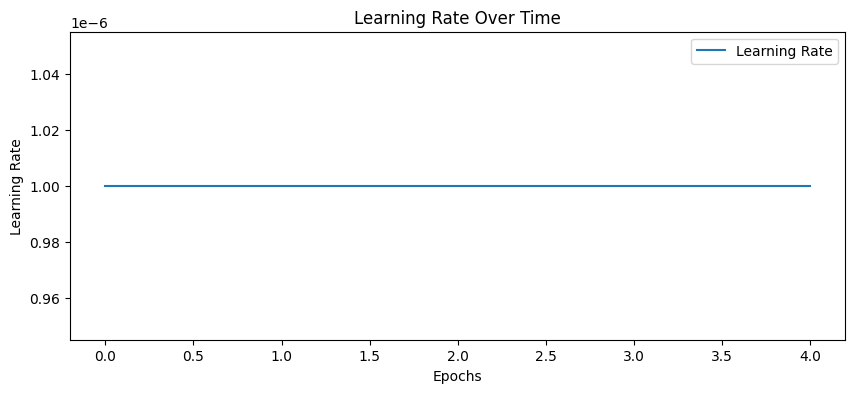

In [13]:
print("Plotting should start now")
plt.figure(figsize=(10, 4))

# For constant learning rate
if hasattr(model.optimizer, 'lr'):
    # If it's a simple float/constant LR
    if hasattr(model.optimizer.lr, 'numpy'):
        lr_value = model.optimizer.lr.numpy()
    else:
        lr_value = float(model.optimizer.lr)
    
    lrs = [lr_value] * len(history.history['loss'])
    plt.plot(lrs, label='Learning Rate')
elif hasattr(model.optimizer, 'learning_rate'):
    # For newer TF/Keras versions
    if hasattr(model.optimizer.learning_rate, 'numpy'):
        lr_value = model.optimizer.learning_rate.numpy()
    else:
        lr_value = float(model.optimizer.learning_rate)
    
    lrs = [lr_value] * len(history.history['loss'])
    plt.plot(lrs, label='Learning Rate')
else:
    print("Could not access learning rate attribute")

plt.title('Learning Rate Over Time')
plt.xlabel('Epochs')
plt.ylabel('Learning Rate')
plt.legend()
plt.show()

## 🧠 Grad-CAM: Visualize Model Focus Areas

In [24]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

def preprocess_image(img_path, target_size=(150, 150)):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=target_size)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)
    return img_array, np.array(img) / 255.0  # Return both model input and original image


In [25]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Build a model that maps the input image to the activations and predictions
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_output = predictions[:, pred_index]

    # Get the gradients of the class output w.r.t. the convolutional layer
    grads = tape.gradient(class_output, conv_outputs)

    # Compute the guided gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel by the corresponding pooled gradient
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()


In [36]:
def display_gradcam(img_path, model, last_conv_layer_name='rescaling', alpha=0.4):
    img_array, original_img = preprocess_image(img_path)
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    # Resize heatmap to image size
    heatmap = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))
    heatmap = np.uint8(255 * heatmap)

    # Apply colormap
    jet = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Overlay heatmap
    superimposed_img = jet * alpha + np.uint8(255 * original_img)
    superimposed_img = np.uint8(superimposed_img)

    # Display
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.title("Original Image")
    plt.imshow(original_img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Grad-CAM")
    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.show()


In [29]:
display_gradcam("Brain_Stroke_CT_Dataset/Training/Ischemia/10024-checkpoint.png", model)


AttributeError: The layer sequential_1 has never been called and thus has no defined output.